# Импорт библиотек

In [1]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
pd.options.display.max_columns = 100
pd.options.display.max_rows = 64


sns.set_style("white")
sns.set_theme(style="whitegrid")


ASSETS_DIR = "../model_improvement/assets"
os.makedirs(ASSETS_DIR, exist_ok=True)

## Общий обзор датасета

In [3]:
from pathlib import Path

from recsys_utils import load_clients_sample

# Данные лежат в папке data (или в папке из переменной окружения DATA_DIR).
# Для анализа берётся выборка клиентов (около 200 тысяч из 957 тысяч): вся история каждого клиента сохраняется,
# поэтому доли и распределения совпадают с полной таблицей, а ядру хватает памяти.
DATA_DIR = Path(os.getenv("DATA_DIR", "../data"))
SAMPLE_PERCENT = 21

df = load_clients_sample(DATA_DIR / "train_ver2.csv", SAMPLE_PERCENT)

In [4]:
df.describe()

,ncodpers,ind_nuevo,indrel,tipodom,cod_prov,ind_actividad_cliente,renta,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,ind_cder_fin_ult1,ind_cno_fin_ult1,ind_ctju_fin_ult1,ind_ctma_fin_ult1,ind_ctop_fin_ult1,ind_ctpp_fin_ult1,ind_deco_fin_ult1,ind_deme_fin_ult1,ind_dela_fin_ult1,ind_ecue_fin_ult1,ind_fond_fin_ult1,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
count,2.861344e+06,2.855385e+06,2.855385e+06,2855385.0,2.841913e+06,2.855385e+06,2.276063e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.861344e+06,2.857996e+06,2.857996e+06,2.861344e+06
mean,8.350111e+05,5.960702e-02,1.174145e+00,1.0,2.658254e+01,4.570617e-01,1.344780e+05,1.317563e-04,5.556829e-05,6.538354e-01,3.701058e-04,8.092176e-02,9.414806e-03,1.007149e-02,1.290799e-01,4.309094e-02,1.721569e-03,1.703046e-03,4.291200e-02,8.262970e-02,1.870240e-02,6.129287e-03,9.219793e-03,2.447102e-03,5.254244e-02,4.471885e-02,2.588015e-02,3.889431e-03,5.496334e-02,5.948364e-02,1.274712e-01
std,4.319026e+05,2.367574e-01,4.127460e+00,0.0,1.277470e+01,4.981530e-01,2.317585e+05,1.147776e-02,7.454208e-03,4.757465e-01,1.923458e-02,2.727150e-01,9.657210e-02,9.985018e-02,3.352884e-01,2.030619e-01,4.145607e-02,4.123283e-02,2.026588e-01,2.753217e-01,1.354719e-01,7.804948e-02,9.557610e-02,4.940763e-02,2.231182e-01,2.066860e-01,1.587777e-01,6.224391e-02,2.279087e-01,2.365277e-01,3.335001e-01
min,1.588900e+04,0.000000e+00,1.000000e+00,1.0,1.000000e+00,0.000000e+00,1.471230e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.525920e+05,0.000000e+00,1.000000e+00,1.0,1.500000e+01,0.000000e+00,6.868524e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,9.322210e+05,0.000000e+00,1.000000e+00,1.0,2.800000e+01,0.000000e+00,1.019460e+05,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.199880e+06,0.000000e+00,1.000000e+00,1.0,3.500000e+01,1.000000e+00,1.561510e+05,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,1.553688e+06,1.000000e+00,9.900000e+01,1.0,5.200000e+01,1.000000e+00,2.889440e+07,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [5]:
df.head(5)

,fecha_dato,ncodpers,ind_empleado,pais_residencia,sexo,age,fecha_alta,ind_nuevo,antiguedad,indrel,ult_fec_cli_1t,indrel_1mes,tiprel_1mes,indresi,indext,conyuemp,canal_entrada,indfall,tipodom,cod_prov,nomprov,ind_actividad_cliente,renta,segmento,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,ind_cder_fin_ult1,ind_cno_fin_ult1,ind_ctju_fin_ult1,ind_ctma_fin_ult1,ind_ctop_fin_ult1,ind_ctpp_fin_ult1,ind_deco_fin_ult1,ind_deme_fin_ult1,ind_dela_fin_ult1,ind_ecue_fin_ult1,ind_fond_fin_ult1,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1050626,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,8.0,BARCELONA,1.0,NaN,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
1,2015-01-28,1050627,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,13.0,CIUDAD REAL,0.0,65608.35,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
2,2015-01-28,1050598,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,45.0,TOLEDO,1.0,90408.75,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
3,2015-01-28,1050599,N,ES,V,24,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,49.0,ZAMORA,0.0,74780.37,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
4,2015-01-28,1050601,N,ES,V,26,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,45.0,TOLEDO,0.0,120146.49,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0


In [6]:
print("Размер датасета (строки, столбцы):", df.shape)

print("\nПервые 10 строк:")
display(df.head(10))

print("\nИнформация о столбцах:")
df.info()

# Подсчёт пропусков по столбцам
missing_df = (
    df.isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "n_missing"})
)
missing_df["missing_share"] = missing_df["n_missing"] / len(df)

print("\nСтолбцы с наибольшей долей пропусков:")
display(
    missing_df.sort_values("missing_share", ascending=False).head(20)
)

# Разделение на числовые и категориальные признаки
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nЧисловые признаки:")
print(numeric_cols)

print("\nКатегориальные признаки:")
print(categorical_cols)

# Базовые статистики по числовым признакам
print("\nОписательные статистики по числовым признакам:")
describe_num = df[numeric_cols].describe().transpose()
display(describe_num)

# Базовые статистики по категориальным признакам
if len(categorical_cols) > 0:
    print("\nОписательные статистики по категориальным признакам:")
    describe_cat = df[categorical_cols].describe().transpose()
    display(describe_cat)


Размер датасета (строки, столбцы): (2861344, 48)

Первые 10 строк:


,fecha_dato,ncodpers,ind_empleado,pais_residencia,sexo,age,fecha_alta,ind_nuevo,antiguedad,indrel,ult_fec_cli_1t,indrel_1mes,tiprel_1mes,indresi,indext,conyuemp,canal_entrada,indfall,tipodom,cod_prov,nomprov,ind_actividad_cliente,renta,segmento,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,ind_cder_fin_ult1,ind_cno_fin_ult1,ind_ctju_fin_ult1,ind_ctma_fin_ult1,ind_ctop_fin_ult1,ind_ctpp_fin_ult1,ind_deco_fin_ult1,ind_deme_fin_ult1,ind_dela_fin_ult1,ind_ecue_fin_ult1,ind_fond_fin_ult1,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1050626,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,8.0,BARCELONA,1.0,NaN,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
1,2015-01-28,1050627,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,13.0,CIUDAD REAL,0.0,65608.35,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
2,2015-01-28,1050598,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,45.0,TOLEDO,1.0,90408.75,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
3,2015-01-28,1050599,N,ES,V,24,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,49.0,ZAMORA,0.0,74780.37,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
4,2015-01-28,1050601,N,ES,V,26,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,45.0,TOLEDO,0.0,120146.49,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
5,2015-01-28,1050602,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,37.0,SALAMANCA,1.0,91282.71,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
6,2015-01-28,1050603,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,50.0,ZARAGOZA,1.0,131351.94,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
7,2015-01-28,1050628,N,ES,V,22,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,25.0,LERIDA,0.0,NaN,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
8,2015-01-28,1050630,N,ES,V,22,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,S,NaN,KHD,N,1.0,8.0,BARCELONA,0.0,64398.06,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
9,2015-01-28,1050686,N,ES,V,39,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KFC,N,1.0,10.0,CACERES,1.0,37075.26,02 - PARTICULARES,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0.0,0.0,1



Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2861344 entries, 0 to 2861343
Data columns (total 48 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   fecha_dato             object 
 1   ncodpers               int64  
 2   ind_empleado           object 
 3   pais_residencia        object 
 4   sexo                   object 
 5   age                    object 
 6   fecha_alta             object 
 7   ind_nuevo              float64
 8   antiguedad             object 
 9   indrel                 float64
 10  ult_fec_cli_1t         object 
 11  indrel_1mes            object 
 12  tiprel_1mes            object 
 13  indresi                object 
 14  indext                 object 
 15  conyuemp               object 
 16  canal_entrada          object 
 17  indfall                object 
 18  tipodom                float64
 19  cod_prov               float64
 20  nomprov                object 
 21  ind_actividad_cliente  float64


Столбцы с наибольшей долей пропусков:


,column,n_missing,missing_share
15,conyuemp,2860997,0.999879
10,ult_fec_cli_1t,2856270,0.998227
22,renta,585281,0.204548
23,segmento,39524,0.013813
16,canal_entrada,38768,0.013549
11,indrel_1mes,31534,0.011021
12,tiprel_1mes,31534,0.011021
20,nomprov,19431,0.006791
19,cod_prov,19431,0.006791
17,indfall,5959,0.002083



Числовые признаки:
['ncodpers', 'ind_nuevo', 'indrel', 'tipodom', 'cod_prov', 'ind_actividad_cliente', 'renta', 'ind_ahor_fin_ult1', 'ind_aval_fin_ult1', 'ind_cco_fin_ult1', 'ind_cder_fin_ult1', 'ind_cno_fin_ult1', 'ind_ctju_fin_ult1', 'ind_ctma_fin_ult1', 'ind_ctop_fin_ult1', 'ind_ctpp_fin_ult1', 'ind_deco_fin_ult1', 'ind_deme_fin_ult1', 'ind_dela_fin_ult1', 'ind_ecue_fin_ult1', 'ind_fond_fin_ult1', 'ind_hip_fin_ult1', 'ind_plan_fin_ult1', 'ind_pres_fin_ult1', 'ind_reca_fin_ult1', 'ind_tjcr_fin_ult1', 'ind_valo_fin_ult1', 'ind_viv_fin_ult1', 'ind_nomina_ult1', 'ind_nom_pens_ult1', 'ind_recibo_ult1']

Категориальные признаки:
['fecha_dato', 'ind_empleado', 'pais_residencia', 'sexo', 'age', 'fecha_alta', 'antiguedad', 'ult_fec_cli_1t', 'indrel_1mes', 'tiprel_1mes', 'indresi', 'indext', 'conyuemp', 'canal_entrada', 'indfall', 'nomprov', 'segmento']

Описательные статистики по числовым признакам:


,count,mean,std,min,25%,50%,75%,max
ncodpers,2861344.0,835011.067493,431902.587615,15889.00,452592.00,932221.00,1199879.50,1553688.00
ind_nuevo,2855385.0,0.059607,0.236757,0.00,0.00,0.00,0.00,1.00
indrel,2855385.0,1.174145,4.127460,1.00,1.00,1.00,1.00,99.00
tipodom,2855385.0,1.000000,0.000000,1.00,1.00,1.00,1.00,1.00
cod_prov,2841913.0,26.582544,12.774698,1.00,15.00,28.00,35.00,52.00
ind_actividad_cliente,2855385.0,0.457062,0.498153,0.00,0.00,0.00,1.00,1.00
renta,2276063.0,134478.012481,231758.524618,1471.23,68685.24,101946.03,156150.96,28894395.51
ind_ahor_fin_ult1,2861344.0,0.000132,0.011478,0.00,0.00,0.00,0.00,1.00
ind_aval_fin_ult1,2861344.0,0.000056,0.007454,0.00,0.00,0.00,0.00,1.00
ind_cco_fin_ult1,2861344.0,0.653835,0.475747,0.00,0.00,1.00,1.00,1.00



Описательные статистики по категориальным признакам:


,count,unique,top,freq
fecha_dato,2861344,17,2016-05-28,195376
ind_empleado,2855385,4,N,2853776
pais_residencia,2855385,80,ES,2841913
sexo,2855385,2,V,1551078
age,2861344,234,23,112556
fecha_alta,2855385,6369,2014-07-28,11867
antiguedad,2861344,505,0,28111
ult_fec_cli_1t,5074,223,2015-12-24,159
indrel_1mes,2829810,11,1.0,1414137
tiprel_1mes,2829810,5,I,1533025


## Подготовка признаков для анализа

In [7]:
ID_COL = "ncodpers"
DATE_COL = "fecha_dato"
JOIN_DATE_COL = "fecha_alta"

# Продуктовые колонки (бинарные флаги наличия продуктов)
PRODUCT_COLS = sorted([c for c in df.columns if c.startswith("ind_") and c.endswith("_ult1")])

# Колонки, которые не участвуют в EDA признаков как "обычные" фичи
# date/id нужны отдельно для временных разрезов
not_eda_features = [ID_COL, DATE_COL] + PRODUCT_COLS

# Приведение типов для корректного анализа
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[JOIN_DATE_COL] = pd.to_datetime(df[JOIN_DATE_COL], errors="coerce")

df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["antiguedad"] = pd.to_numeric(df["antiguedad"], errors="coerce")

# Колонки с экстремальной долей пропусков
# conyuemp и ult_fec_cli_1t почти полностью пустые, в EDA отдельно фиксируются как непригодные
high_missing_cols = ["conyuemp", "ult_fec_cli_1t"]

# Удаление колонок с почти полной пустотой из дальнейшего анализа признаков
df_eda = df.drop(columns=[c for c in high_missing_cols if c in df.columns]).copy()

# Числовые признаки (кроме id/date и продуктовых флагов)
numeric_cols = [
    c for c in df_eda.select_dtypes(include=["int64", "float64"]).columns
    if c not in not_eda_features
]

# Категориальные признаки (кроме id/date и продуктовых флагов)
categorical_cols = [
    c for c in df_eda.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in not_eda_features
]

# Бинарные категориальные признаки
binary_cols = [
    c for c in categorical_cols
    if df_eda[c].dropna().nunique() == 2
]

# Многокатегориальные признаки
multi_cat_cols = [c for c in categorical_cols if c not in binary_cols]

print("Кол-во продуктовых колонок:", len(PRODUCT_COLS))
print("Примеры продуктовых колонок:", PRODUCT_COLS[:5], "...", PRODUCT_COLS[-5:])
print("Числовые признаки:", numeric_cols)
print("Категориальные признаки:", categorical_cols)
print("Бинарные признаки:", binary_cols)
print("Многокатегориальные признаки:", multi_cat_cols)

print("\nДиапазон дат:", df_eda[DATE_COL].min(), "—", df_eda[DATE_COL].max())
print("Уникальных месяцев:", df_eda[DATE_COL].dt.to_period("M").nunique())


Кол-во продуктовых колонок: 24
Примеры продуктовых колонок: ['ind_ahor_fin_ult1', 'ind_aval_fin_ult1', 'ind_cco_fin_ult1', 'ind_cder_fin_ult1', 'ind_cno_fin_ult1'] ... ['ind_reca_fin_ult1', 'ind_recibo_ult1', 'ind_tjcr_fin_ult1', 'ind_valo_fin_ult1', 'ind_viv_fin_ult1']
Числовые признаки: ['age', 'ind_nuevo', 'antiguedad', 'indrel', 'tipodom', 'cod_prov', 'ind_actividad_cliente', 'renta']
Категориальные признаки: ['ind_empleado', 'pais_residencia', 'sexo', 'indrel_1mes', 'tiprel_1mes', 'indresi', 'indext', 'canal_entrada', 'indfall', 'nomprov', 'segmento']
Бинарные признаки: ['sexo', 'indresi', 'indext', 'indfall']
Многокатегориальные признаки: ['ind_empleado', 'pais_residencia', 'indrel_1mes', 'tiprel_1mes', 'canal_entrada', 'nomprov', 'segmento']

Диапазон дат: 2015-01-28 00:00:00 — 2016-05-28 00:00:00
Уникальных месяцев: 17


,share_1,cnt_1
ind_cco_fin_ult1,0.653835,1870848.0
ind_ctop_fin_ult1,0.129080,369342.0
ind_recibo_ult1,0.127471,364739.0
ind_ecue_fin_ult1,0.082630,236432.0
ind_cno_fin_ult1,0.080922,231545.0
ind_nom_pens_ult1,0.059484,170004.0
ind_nomina_ult1,0.054963,157085.0
ind_reca_fin_ult1,0.052542,150342.0
ind_tjcr_fin_ult1,0.044719,127956.0
ind_ctpp_fin_ult1,0.043091,123298.0


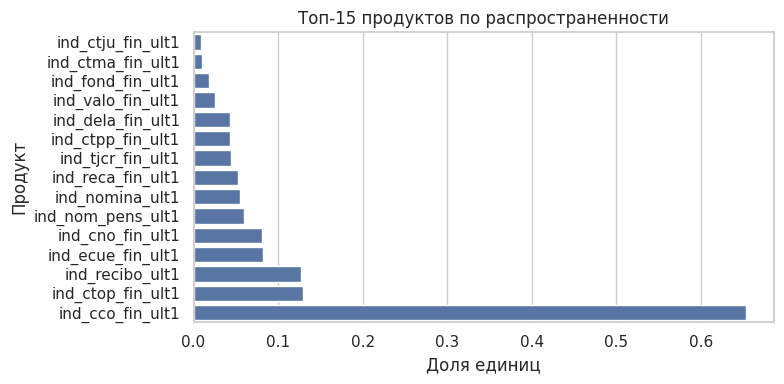

,value
count,300000.000000
mean,1.462043
std,1.522888
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,14.000000


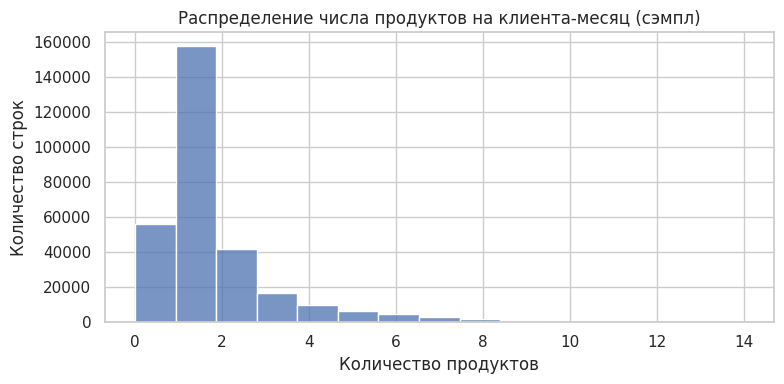

Доля строк, где у клиента есть хотя бы один продукт: 0.8119


In [8]:
# Продуктовые признаки: частоты и распределения

# Частоты владения продуктами (по всей таблице)
product_stats = (
    df_eda[PRODUCT_COLS]
    .agg(["mean", "sum"])
    .T
    .rename(columns={"mean": "share_1", "sum": "cnt_1"})
    .sort_values("share_1", ascending=False)
)

display(product_stats.head(10))
product_stats.to_csv(os.path.join(ASSETS_DIR, "product_prevalence.csv"), index=True)

# График: топ продуктов по доле единиц
top_n = 15
top_products = product_stats.head(top_n).iloc[::-1]

plt.figure(figsize=(8, 4))
sns.barplot(x=top_products["share_1"], y=top_products.index, orient="h")
plt.title(f"Топ-{top_n} продуктов по распространенности")
plt.xlabel("Доля единиц")
plt.ylabel("Продукт")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "top_products_prevalence.png"))
plt.show()

# Количество продуктов в строке (сэмпл, чтобы не создавать колонку на весь df_eda)
sample_size = 300_000
df_np = df_eda[PRODUCT_COLS].sample(n=min(sample_size, len(df_eda)), random_state=42)

n_products_sample = df_np.sum(axis=1).astype("int16")

display(n_products_sample.describe().to_frame(name="value"))
n_products_sample.describe().to_frame(name="value").to_csv(os.path.join(ASSETS_DIR, "n_products_describe_sample.csv"))

plt.figure(figsize=(8, 4))
sns.histplot(n_products_sample, bins=int(n_products_sample.max()) + 1)
plt.title("Распределение числа продуктов на клиента-месяц (сэмпл)")
plt.xlabel("Количество продуктов")
plt.ylabel("Количество строк")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "n_products_distribution_sample.png"))
plt.show()

# Доля строк с хотя бы одним продуктом (по всей таблице, но без сохранения колонки)
share_any_product = (df_eda[PRODUCT_COLS].sum(axis=1) > 0).mean()
print("Доля строк, где у клиента есть хотя бы один продукт:", round(float(share_any_product), 4))


,new_cnt
ind_recibo_ult1,31842
ind_nom_pens_ult1,17645
ind_nomina_ult1,15406
ind_cco_fin_ult1,14740
ind_tjcr_fin_ult1,14399
ind_cno_fin_ult1,7838
ind_ecue_fin_ult1,5625
ind_dela_fin_ult1,2637
ind_reca_fin_ult1,1956
ind_ctma_fin_ult1,1511


fecha_dato
2015-01        0
2015-02     6511
2015-03     6801
2015-04     6272
2015-05     5620
2015-06     8641
2015-07     7066
2015-08     6009
2015-09     7520
2015-10     8208
2015-11     7253
2015-12     8919
2016-01     6522
2016-02    10282
2016-03     7364
2016-04     7003
2016-05     7699
Freq: M, dtype: int16

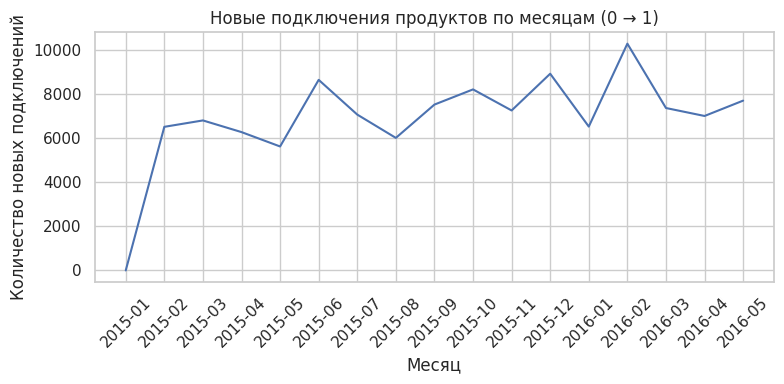

Доля строк с хотя бы одним новым продуктом: 0.0327


In [9]:
# Новые подключения продуктов (0 -> 1) и динамика по времени

df_sorted = df_eda[[ID_COL, DATE_COL] + PRODUCT_COLS].sort_values([ID_COL, DATE_COL])

# Лаги продуктовых флагов по клиенту
prev_products = df_sorted.groupby(ID_COL)[PRODUCT_COLS].shift(1)

# Новое подключение: было 0, стало 1
new_mask = (df_sorted[PRODUCT_COLS].eq(1) & prev_products.eq(0))

# Сколько новых подключений каждого продукта (итого за период)
new_product_stats = (
    new_mask.sum()
    .sort_values(ascending=False)
    .to_frame("new_cnt")
)

display(new_product_stats.head(10))
new_product_stats.to_csv(os.path.join(ASSETS_DIR, "new_product_counts_total.csv"), index=True)

# Сколько новых подключений в строке (в текущий клиент-месяц)
new_total_per_row = new_mask.sum(axis=1).astype("int16")

# Динамика по месяцам
new_per_month = (
    new_total_per_row
    .groupby(df_sorted[DATE_COL].dt.to_period("M"))
    .sum()
    .sort_index()
)

display(new_per_month)
new_per_month.to_csv(os.path.join(ASSETS_DIR, "new_products_per_month.csv"), index=True)

plt.figure(figsize=(8, 4))
sns.lineplot(x=new_per_month.index.astype(str), y=new_per_month.values)
plt.title("Новые подключения продуктов по месяцам (0 → 1)")
plt.xlabel("Месяц")
plt.ylabel("Количество новых подключений")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "new_products_per_month.png"))
plt.show()

# Доля строк с хотя бы одним новым продуктом
has_any_new = (new_total_per_row > 0).mean()
print("Доля строк с хотя бы одним новым продуктом:", round(float(has_any_new), 4))


Средняя вероятность нового продукта: 0.0327


has_new_product,mean_no_new,mean_with_new
age,40.055624,42.569816
ind_nuevo,0.057437,0.131938
antiguedad,79.144591,83.569509
indrel,1.194586,1.060326
tipodom,1.000000,1.000000
cod_prov,26.548293,26.972737
ind_actividad_cliente,0.440134,0.951472
renta,133788.007159,144156.695913


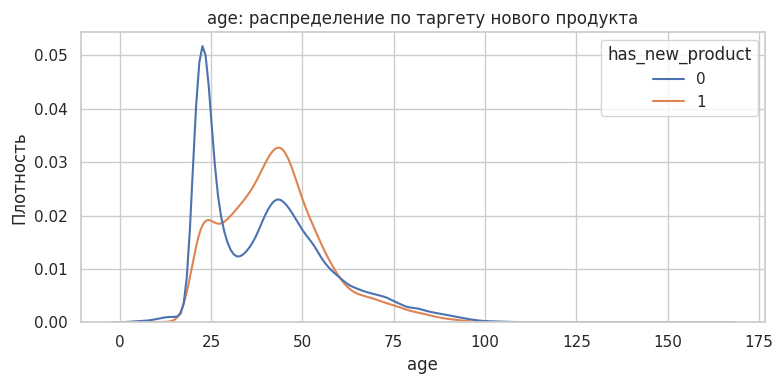

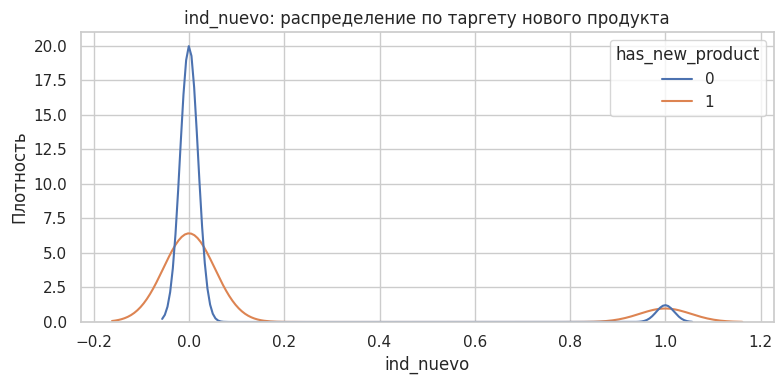

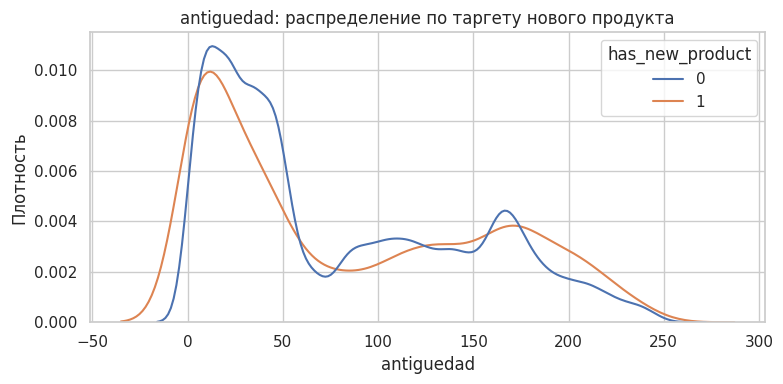

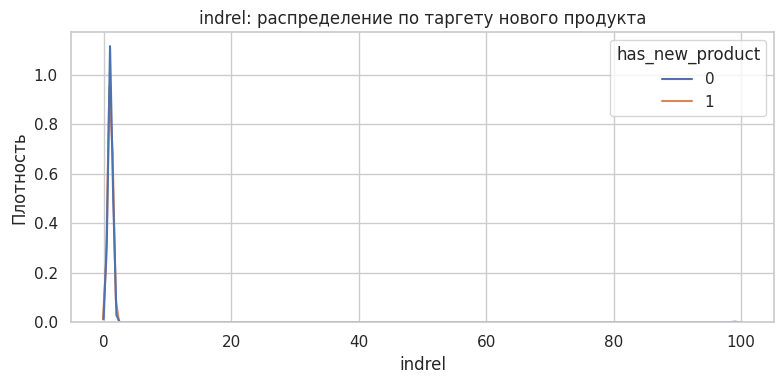

/tmp/ipykernel_30/373961757.py:35: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


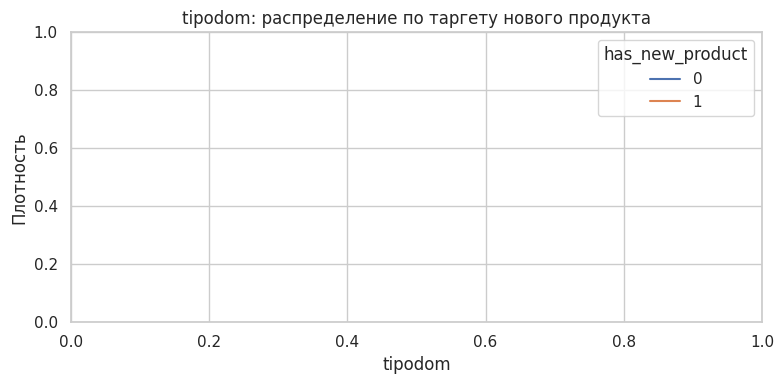

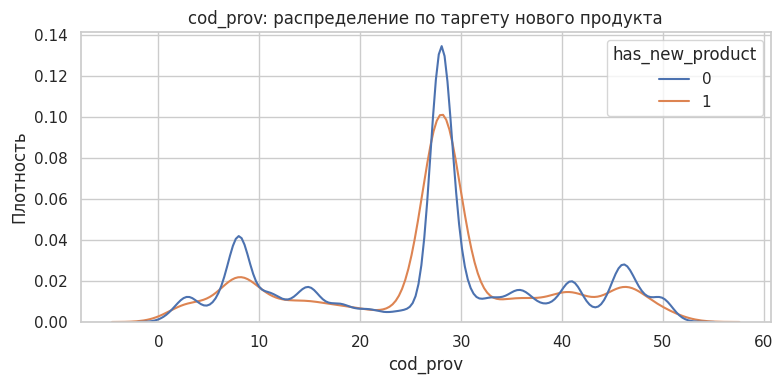

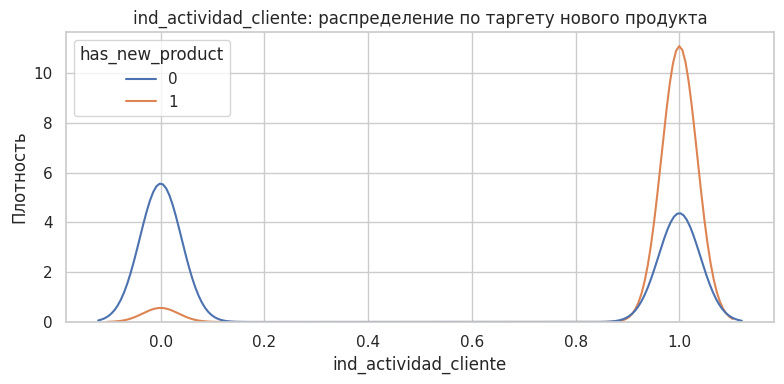

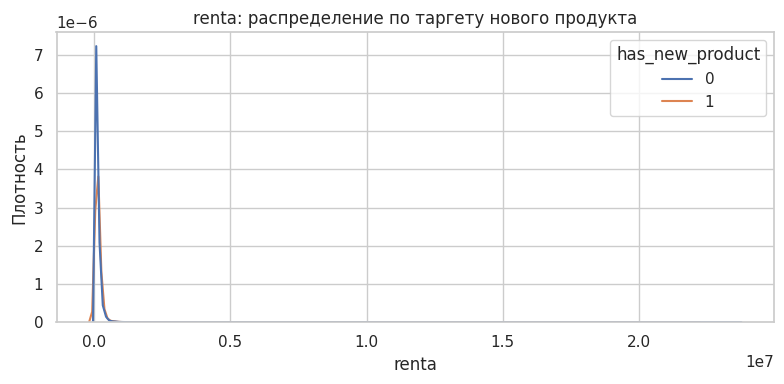

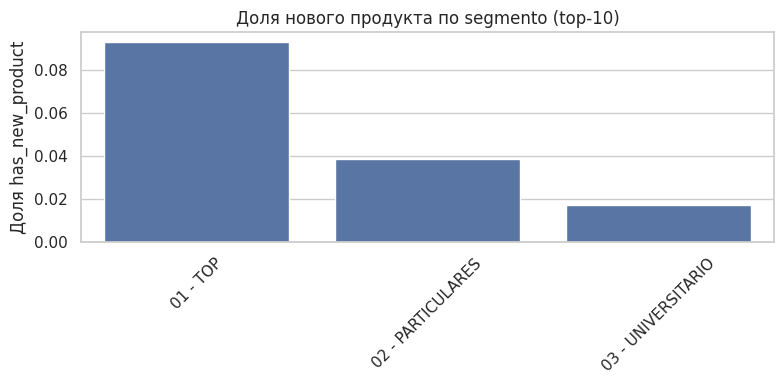

In [10]:
# Анализ клиентских признаков относительно новых продуктов

df_sorted = df_sorted.copy()
df_sorted["has_new_product"] = (new_total_per_row > 0).astype("int8")

target_rate = df_sorted["has_new_product"].mean()
print("Средняя вероятность нового продукта:", round(float(target_rate), 4))

# Для анализа признаков нужны клиентские признаки.
# Чтобы не тащить весь df_eda, берём сэмпл индексов из df_sorted и по ним подтягиваем признаки из df_eda.
sample_size = 300_000
sample_idx = df_sorted.index.to_series().sample(
    n=min(sample_size, len(df_sorted)),
    random_state=42
)

df_sample = df_eda.loc[sample_idx, numeric_cols + multi_cat_cols].copy()
df_sample["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

# Средние по числовым признакам
numeric_feature_stats = (
    df_sample
    .groupby("has_new_product")[numeric_cols]
    .mean()
    .T
    .rename(columns={0: "mean_no_new", 1: "mean_with_new"})
)

display(numeric_feature_stats)
numeric_feature_stats.to_csv(os.path.join(ASSETS_DIR, "numeric_features_vs_new_product.csv"))

# Графики распределений числовых признаков (сэмпл)
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.kdeplot(
        data=df_sample,
        x=col,
        hue="has_new_product",
        common_norm=False
    )
    plt.title(f"{col}: распределение по таргету нового продукта")
    plt.xlabel(col)
    plt.ylabel("Плотность")
    plt.tight_layout()
    plt.savefig(os.path.join(ASSETS_DIR, f"{col}_by_target.png"))
    plt.show()

# Категориальные признаки: доля нового продукта по категориям (top-N)
top_n = 15
for col in multi_cat_cols:
    vc = df_sample[col].value_counts(dropna=False)
    top_vals = vc.head(top_n).index

    tmp = (
        df_sample[df_sample[col].isin(top_vals)]
        .groupby(col, dropna=False)["has_new_product"]
        .mean()
        .sort_values(ascending=False)
    )

    tmp.to_csv(os.path.join(ASSETS_DIR, f"{col}_target_rate_top{top_n}.csv"))

# Визуализация segmento (top-N, чтобы не падало)
col = "segmento"
vc = df_sample[col].value_counts(dropna=False)
top_vals = vc.head(10).index

plot_df = (
    df_sample[df_sample[col].isin(top_vals)]
    .groupby(col, dropna=False)["has_new_product"]
    .mean()
    .reset_index()
    .sort_values("has_new_product", ascending=False)
)

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x=col, y="has_new_product")
plt.title("Доля нового продукта по segmento (top-10)")
plt.xlabel("")
plt.ylabel("Доля has_new_product")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "segmento_new_product_rate_top10.png"))
plt.show()


### Корреляция числовых признаков


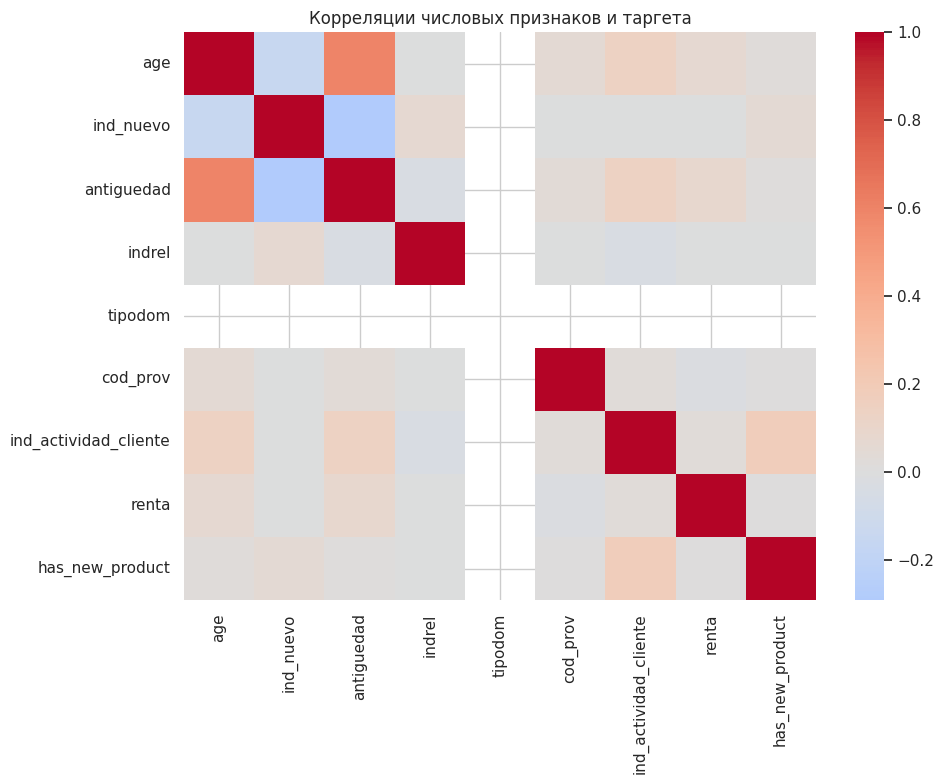

In [11]:
# Корреляции числовых признаков и таргета (на сэмпле)

corr_cols = numeric_cols + ["has_new_product"]

corr = df_sample[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Корреляции числовых признаков и таргета")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "numeric_correlation_heatmap.png"))
plt.show()


### Частоты значений бинарных признаков


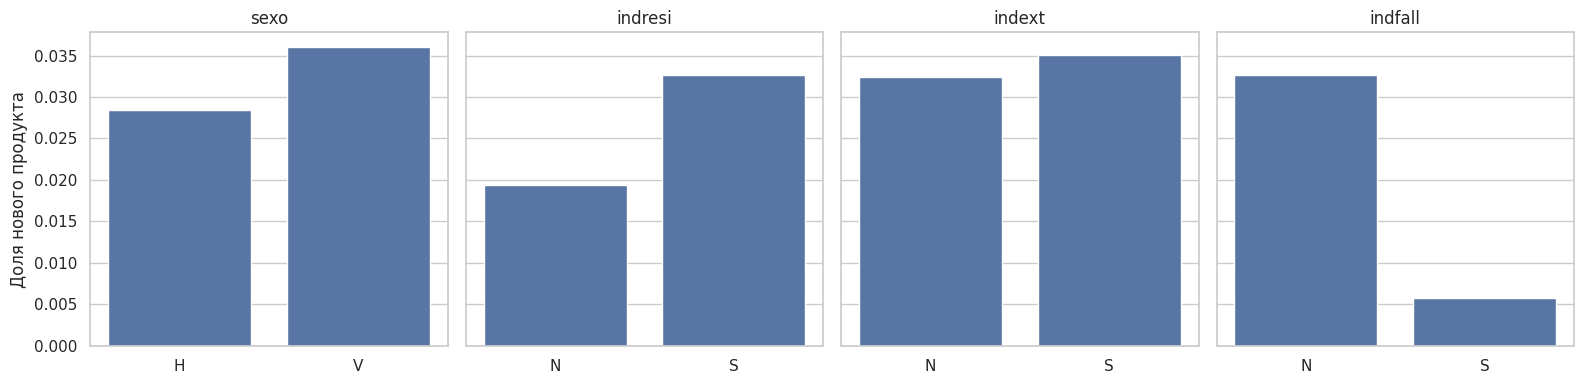

In [12]:
binary_categorical_cols = ["sexo", "indresi", "indext", "indfall"]

# если sample_idx уже есть из предыдущих ячеек
df_sample_bin = df_eda.loc[sample_idx, binary_categorical_cols].copy()
df_sample_bin["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(binary_categorical_cols),
    figsize=(4 * len(binary_categorical_cols), 4),
    sharey=True
)

for ax, col in zip(axes, binary_categorical_cols):
    plot_df = (
        df_sample_bin
        .groupby(col, as_index=False)["has_new_product"]
        .mean()
    )

    sns.barplot(data=plot_df, x=col, y="has_new_product", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Доля нового продукта")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "binary_categorical_new_product_rate.png"))
plt.show()


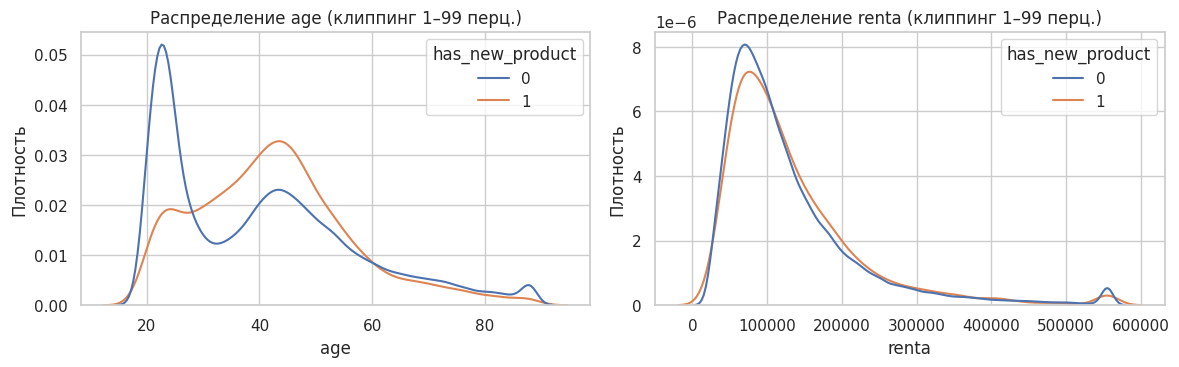

In [13]:
# Распределения age и renta с клиппингом (1–99 перцентили) на сэмпле

clip_cols = ["age", "renta"]

# df_sample должен содержать: age, renta, has_new_product
df_sample_ar = df_eda.loc[sample_idx, clip_cols].copy()
df_sample_ar["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

fig, axes = plt.subplots(nrows=1, ncols=len(clip_cols), figsize=(12, 4))

for ax, col in zip(axes, clip_cols):
    valid = df_sample_ar[col].dropna()
    q1, q99 = valid.quantile([0.01, 0.99])

    plot_df = df_sample_ar[[col, "has_new_product"]].dropna(subset=[col]).copy()
    plot_df[col] = plot_df[col].clip(lower=q1, upper=q99)

    sns.kdeplot(
        data=plot_df,
        x=col,
        hue="has_new_product",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Распределение {col} (клиппинг 1–99 перц.)")
    ax.set_xlabel(col)
    ax.set_ylabel("Плотность")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "age_renta_clipped_distributions.png"))
plt.show()


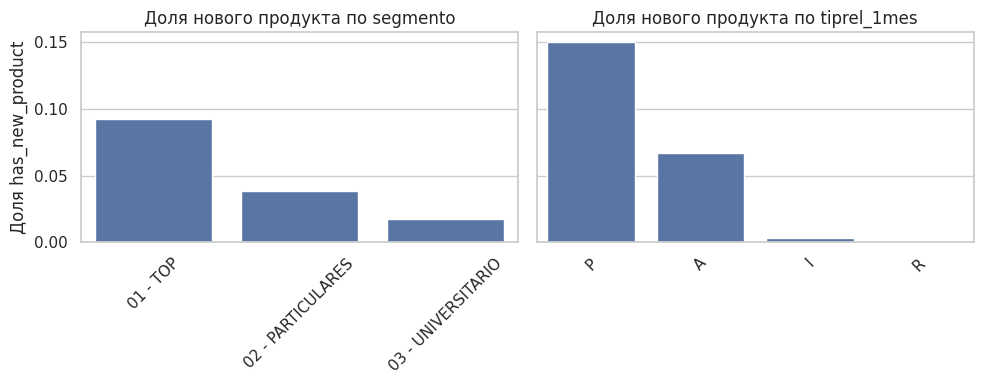

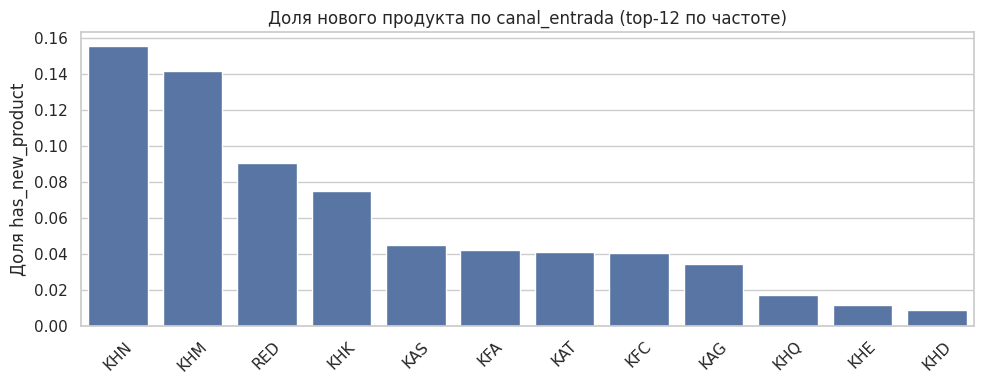

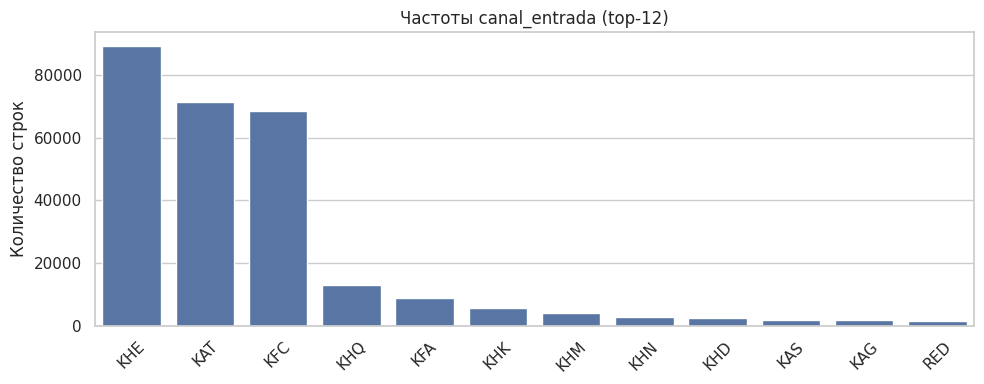

In [14]:
# Категориальные признаки: доля нового продукта

cat_cols = ["segmento", "tiprel_1mes"]

df_sample_cat = df_eda.loc[sample_idx, cat_cols + ["canal_entrada"]].copy()
df_sample_cat["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

fig, axes = plt.subplots(nrows=1, ncols=len(cat_cols), figsize=(10, 4), sharey=True)

for ax, col in zip(axes, cat_cols):
    plot_df = (
        df_sample_cat
        .groupby(col, as_index=False)["has_new_product"]
        .mean()
        .sort_values("has_new_product", ascending=False)
    )

    sns.barplot(
        data=plot_df,
        x=col,
        y="has_new_product",
        ax=ax
    )

    ax.set_title(f"Доля нового продукта по {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Доля has_new_product")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "categorical_new_product_rate_segmento_tiprel.png"))
plt.show()

top_n = 12
top_canal = df_sample_cat["canal_entrada"].value_counts().head(top_n).index

canal_df = df_sample_cat[df_sample_cat["canal_entrada"].isin(top_canal)]

plot_df_rate = (
    canal_df
    .groupby("canal_entrada", as_index=False)["has_new_product"]
    .mean()
    .sort_values("has_new_product", ascending=False)
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=plot_df_rate,
    x="canal_entrada",
    y="has_new_product"
)
plt.title(f"Доля нового продукта по canal_entrada (top-{top_n} по частоте)")
plt.xlabel("")
plt.ylabel("Доля has_new_product")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "canal_entrada_new_product_rate_topN.png"))
plt.show()


vc = df_sample_cat["canal_entrada"].value_counts().head(top_n)

plot_df_freq = vc.rename_axis("canal_entrada").reset_index(name="cnt")

plt.figure(figsize=(10, 4))
sns.barplot(
    data=plot_df_freq,
    x="canal_entrada",
    y="cnt"
)
plt.title(f"Частоты canal_entrada (top-{top_n})")
plt.xlabel("")
plt.ylabel("Количество строк")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "canal_entrada_freq_topN.png"))
plt.show()


<Figure size 1000x400 with 0 Axes>

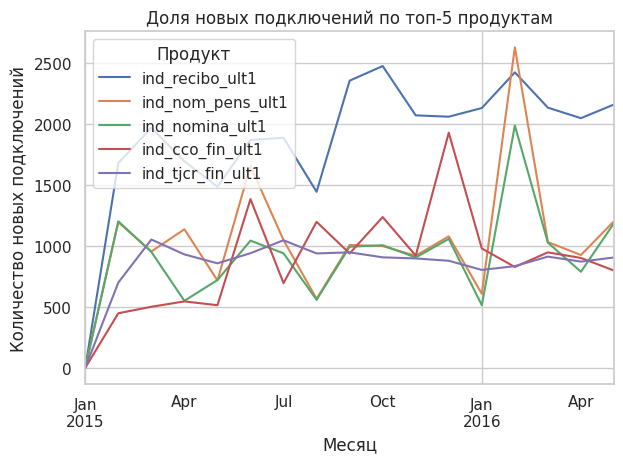

In [15]:
top_k = 5

new_long = (
    new_mask
    .assign(month=df_sorted[DATE_COL].dt.to_period("M"))
    .groupby("month")[PRODUCT_COLS]
    .sum()
)

top_products = new_long.sum().sort_values(ascending=False).head(top_k).index

plot_df = new_long[top_products]

plt.figure(figsize=(10, 4))
plot_df.plot()
plt.title("Доля новых подключений по топ-5 продуктам")
plt.xlabel("Месяц")
plt.ylabel("Количество новых подключений")
plt.legend(title="Продукт")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "top_products_new_by_month.png"))
plt.show()


# Выводы после EDA

EDA: выводы по данным и постановке задачи
1. Таргет: новые подключения продуктов (0 → 1)
- Новым подключением считается переход значения продуктового флага из 0 в 1 на уровне клиент–продукт–месяц.
- Общее количество новых подключений по месяцам после первого месяца стабильно, без деградации по времени.
- Доля клиентов с хотя бы одним новым продуктом в месяц находится в диапазоне ~3–5% и не демонстрирует выраженного тренда.
- Наблюдаются локальные пики новых подключений (в середине 2015 года и в начале 2016 года), что указывает на возможную сезонность или кампанийный эффект.
- Новые подключения распределены неравномерно по продуктам: небольшое число продуктов формирует основную долю всех 0→1 событий.

Вывод: таргет стабилен во времени, пригоден для временного разбиения и обучения рекомендательной модели без риска временного сдвига.

2. Продукты и структура каталога
- Каталог состоит из 24 продуктов с выраженной неравномерностью распространённости.
- Один продукт (ind_cco_fin_ult1) существенно доминирует по доле владения.
- Большинство клиентов в среднем имеют 1–2 продукта; далее наблюдается быстро убывающий хвост.
- Новые подключения также концентрируются в нескольких наиболее массовых продуктах.

Вывод: присутствует выраженный popularity bias, который необходимо учитывать при построении рекомендаций и выборе метрик.

3. Признаки: различия по факту нового продукта (EDA-индикатор)
3.1. Числовые признаки
- ind_actividad_cliente — наиболее сильный разделяющий признак; клиенты с новым продуктом существенно чаще активны.
- age — распределения различаются, группа с новым продуктом смещена.
- renta — различия присутствуют, но выражены умеренно; распределение с тяжёлым хвостом.
- antiguedad — форма распределений различается, эффект умеренный.
- ind_nuevo — информативен, различия между группами заметны.

3.2. Бинарные категориальные признаки
- sexo, indresi, indext, indfall — различия по доле нового продукта присутствуют, но не являются доминирующими.
- indfall демонстрирует заметный перепад долей.

3.3. Мультикатегориальные признаки
- segmento — выраженные различия: сегмент TOP имеет наибольшую долю новых подключений.
- tiprel_1mes — сильные различия между категориями (P, A против I, R).
- canal_entrada — сильный перекос по частотам и заметные различия по доле нового продукта; требует агрегации (top-N + other).

3.4. Малополезные признаки
- tipodom — практически константен, информативность низкая.
- indrel — распределение сильно сосредоточено в одной точке, полезность ограничена.

4. Корреляции числовых признаков
- Линейные корреляции числовых признаков с индикатором нового продукта в целом низкие.
- Наиболее заметная связь наблюдается у ind_actividad_cliente.
- Остальные признаки демонстрируют слабые или близкие к нулю корреляции.

Вывод: ожидается нелинейная и комбинированная зависимость, что обосновывает использование моделей ранжирования на основе градиентного бустинга.

5. Генерация дополнительных признаков (для ранжирования)

На основании EDA и ограничений проекта (объём данных, ресурсы виртуальной машины, требования к воспроизводимости и времени обучения) признаки были разделены на реализованные в проекте и потенциально возможные, но исключённые из реализации.

5.1. Реализованные признаки (используются в modeling)

5.1.1. История пользователя (t−1 snapshot)

Признаки рассчитываются на момент предыдущего месяца и используются как пользовательский контекст при ранжировании кандидатов:

- Количество продуктов у пользователя в предыдущем месяце

Отражает степень вовлечённости клиента и насыщенность продуктового портфеля.

- Флаг наличия нового подключения в предыдущем месяце

Учитывает эффект инерции: клиенты, недавно подключившие продукт, чаще совершают повторные подключения.

- Количество месяцев с новым подключением за последние 3 месяца

Характеризует краткосрочную динамику активности без использования длинных временных окон.

- Количество месяцев с последнего нового подключения

Отражает «давность» последней продуктовой активности пользователя.

Данные признаки:

- вычисляются один раз по обучающему периоду,
- не зависят от кандидатов,
- легко воспроизводимы в production-сценарии.

Месяц как категориальный признак (учёт сезонности).

5.2. Потенциальные признаки, не реализованные в проекте

Следующие группы признаков рассматривались, но не были реализованы осознанно в рамках данного проекта.

5.2.1. Признаки продукта

Частота новых подключений продукта (0→1). Частота новых подключений в скользящем временном окне (например, последние 3 месяца)

Причина исключения:
- ограниченный размер каталога (24 продукта),
- высокий риск усиления popularity bias,
- ограниченный вклад относительно уже используемых кандидатных стратегий.

5.2.2. Признаки пары пользователь–продукт

Co-occurrence продуктов на основе совместного владения. Суммарная и максимальная co-occurrence с текущим набором продуктов пользователя

Причина исключения:
- высокая вычислительная сложность,
- значительное потребление памяти,
- необходимость отдельного пайплайна расчёта и хранения матриц,
- отсутствие критической необходимости для демонстрации основного подхода.

5.2.3. Более сложные временные признаки

Длинные временные окна (6–12 месяцев). Временные тренды на уровне пользователя или продукта

Причина исключения:
- рост вычислительной стоимости,
- усложнение production-инференса,
- ограниченный прирост качества для учебного проекта.


6. Метрики качества рекомендаций

Основные
- Precision@k
- Recall@k
- Coverage@k по пользователям
- Coverage@k по продуктам

Дополнительные (при наличии времени)
- Novelty@k
- Diversity@k

Выбор метрик ориентирован на баланс между точностью рекомендаций и снижением popularity bias при ограниченном размере каталога.

# Логирование артефактов в MLflow

In [16]:
import mlflow

In [17]:
from pathlib import Path

ASSETS_DIR = Path("../model_improvement/assets").resolve()

if not ASSETS_DIR.exists():
    raise FileNotFoundError(f"ASSETS_DIR not found: {ASSETS_DIR}")

# MLflow
# адрес Tracking Server задаётся переменной окружения (по умолчанию локальный сервер из services/run_mlflow.sh)
TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
EXPERIMENT_NAME = "bank_products_recsys"
RUN_NAME = "eda_artifacts"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # Логируем все файлы из assets в артефакты MLflow в папку eda/
    mlflow.log_artifacts(str(ASSETS_DIR), artifact_path="eda")

run_id

2026/10/20 12:21:59 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



'4094dc98a5d149f6bc400b825bec40a3'